<a href="https://colab.research.google.com/github/mohammedEhab2235/Car-rental-/blob/main/video_games_sales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
df=pd.read_csv("vgchartz-2024.csv")
df.head()

,img,title,console,genre,publisher,developer,critic_score,total_sales,na_sales,jp_sales,pal_sales,other_sales,release_date,last_update
0,/games/boxart/full_6510540AmericaFrontccc.jpg,Grand Theft Auto V,PS3,Action,Rockstar Games,Rockstar North,9.4,20.32,6.37,0.99,9.85,3.12,2013-09-17,NaN
1,/games/boxart/full_5563178AmericaFrontccc.jpg,Grand Theft Auto V,PS4,Action,Rockstar Games,Rockstar North,9.7,19.39,6.06,0.60,9.71,3.02,2014-11-18,2018-01-03
2,/games/boxart/827563ccc.jpg,Grand Theft Auto: Vice City,PS2,Action,Rockstar Games,Rockstar North,9.6,16.15,8.41,0.47,5.49,1.78,2002-10-28,NaN
3,/games/boxart/full_9218923AmericaFrontccc.jpg,Grand Theft Auto V,X360,Action,Rockstar Games,Rockstar North,NaN,15.86,9.06,0.06,5.33,1.42,2013-09-17,NaN
4,/games/boxart/full_4990510AmericaFrontccc.jpg,Call of Duty: Black Ops 3,PS4,Shooter,Activision,Treyarch,8.1,15.09,6.18,0.41,6.05,2.44,2015-11-06,2018-01-14


### since the img column is not useful in our project so i removed it

In [9]:
df.drop(columns=['img'], inplace=True)
df.head()

,title,console,genre,publisher,developer,critic_score,total_sales,na_sales,jp_sales,pal_sales,other_sales,release_date,last_update
0,Grand Theft Auto V,PS3,Action,Rockstar Games,Rockstar North,9.4,20.32,6.37,0.99,9.85,3.12,2013-09-17,NaN
1,Grand Theft Auto V,PS4,Action,Rockstar Games,Rockstar North,9.7,19.39,6.06,0.60,9.71,3.02,2014-11-18,2018-01-03
2,Grand Theft Auto: Vice City,PS2,Action,Rockstar Games,Rockstar North,9.6,16.15,8.41,0.47,5.49,1.78,2002-10-28,NaN
3,Grand Theft Auto V,X360,Action,Rockstar Games,Rockstar North,NaN,15.86,9.06,0.06,5.33,1.42,2013-09-17,NaN
4,Call of Duty: Black Ops 3,PS4,Shooter,Activision,Treyarch,8.1,15.09,6.18,0.41,6.05,2.44,2015-11-06,2018-01-14


### Which titles sold the most worldwide?


In [10]:
most_sold_title = df[['title', 'console', 'genre', 'total_sales']]
most_sold_title = most_sold_title.sort_values(by='total_sales', ascending=False).reset_index(drop=True)
most_sold_title.index = most_sold_title.index + 1
top_10_most_sold_titles = most_sold_title.head(10)
top_10_most_sold_titles.to_csv('top_10_most_sold_titles.csv', index=False)
top_10_most_sold_titles

,title,console,genre,total_sales
1,Grand Theft Auto V,PS3,Action,20.32
2,Grand Theft Auto V,PS4,Action,19.39
3,Grand Theft Auto: Vice City,PS2,Action,16.15
4,Grand Theft Auto V,X360,Action,15.86
5,Call of Duty: Black Ops 3,PS4,Shooter,15.09
6,Call of Duty: Modern Warfare 3,X360,Shooter,14.82
7,Call of Duty: Black Ops,X360,Shooter,14.74
8,Red Dead Redemption 2,PS4,Action-Adventure,13.94
9,Call of Duty: Black Ops II,X360,Shooter,13.86
10,Call of Duty: Black Ops II,PS3,Shooter,13.80


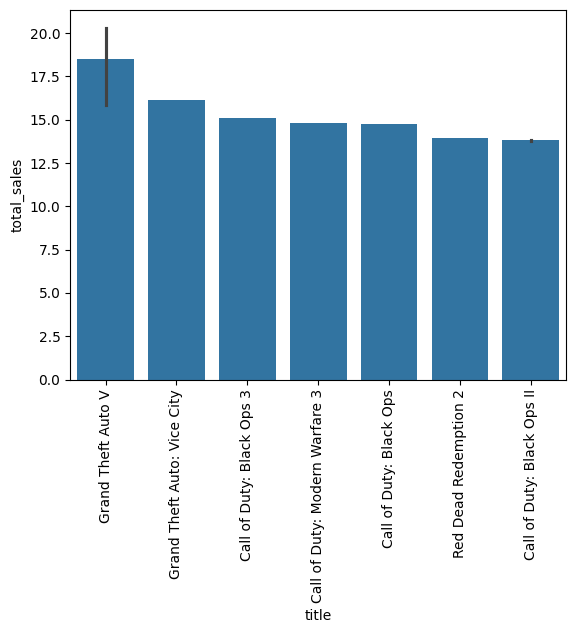

In [11]:
sns.barplot(x='title', y='total_sales', data=top_10_most_sold_titles)
plt.xticks(rotation=90)
plt.show()

###Years with the most sales and trend line to see if the market is growing or not

In [12]:
# Reload the raw release_date column from the original CSV to ensure correct parsing
original_df = pd.read_csv('vgchartz-2024.csv', usecols=['release_date'])
df['release_date'] = pd.to_datetime(original_df['release_date'], errors='coerce').dt.year
df

,title,console,genre,publisher,developer,critic_score,total_sales,na_sales,jp_sales,pal_sales,other_sales,release_date,last_update
0,Grand Theft Auto V,PS3,Action,Rockstar Games,Rockstar North,9.4,20.32,6.37,0.99,9.85,3.12,2013.0,NaN
1,Grand Theft Auto V,PS4,Action,Rockstar Games,Rockstar North,9.7,19.39,6.06,0.60,9.71,3.02,2014.0,2018-01-03
2,Grand Theft Auto: Vice City,PS2,Action,Rockstar Games,Rockstar North,9.6,16.15,8.41,0.47,5.49,1.78,2002.0,NaN
3,Grand Theft Auto V,X360,Action,Rockstar Games,Rockstar North,NaN,15.86,9.06,0.06,5.33,1.42,2013.0,NaN
4,Call of Duty: Black Ops 3,PS4,Shooter,Activision,Treyarch,8.1,15.09,6.18,0.41,6.05,2.44,2015.0,2018-01-14
...,...,...,...,...,...,...,...,...,...,...,...,...,...
64011,XBlaze Lost: Memories,PC,Visual Novel,Aksys Games,Arc System Works,NaN,NaN,NaN,NaN,NaN,NaN,2016.0,2019-01-28
64012,"Yoru, Tomosu",PS4,Visual Novel,Nippon Ichi Software,Nippon Ichi Software,NaN,NaN,NaN,NaN,NaN,NaN,2020.0,2020-05-09
64013,"Yoru, Tomosu",NS,Visual Novel,Nippon Ichi Software,Nippon Ichi Software,NaN,NaN,NaN,NaN,NaN,NaN,2020.0,2020-05-09
64014,Yunohana SpRING! ~Mellow Times~,NS,Visual Novel,Idea Factory,Otomate,NaN,NaN,NaN,NaN,NaN,NaN,2019.0,2019-02-24


In [13]:
# Convert the now corrected release_date column to nullable Int64
df['release_date'] = df['release_date'].astype('Int64')
df.head(10)

,title,console,genre,publisher,developer,critic_score,total_sales,na_sales,jp_sales,pal_sales,other_sales,release_date,last_update
0,Grand Theft Auto V,PS3,Action,Rockstar Games,Rockstar North,9.4,20.32,6.37,0.99,9.85,3.12,2013,NaN
1,Grand Theft Auto V,PS4,Action,Rockstar Games,Rockstar North,9.7,19.39,6.06,0.60,9.71,3.02,2014,2018-01-03
2,Grand Theft Auto: Vice City,PS2,Action,Rockstar Games,Rockstar North,9.6,16.15,8.41,0.47,5.49,1.78,2002,NaN
3,Grand Theft Auto V,X360,Action,Rockstar Games,Rockstar North,NaN,15.86,9.06,0.06,5.33,1.42,2013,NaN
4,Call of Duty: Black Ops 3,PS4,Shooter,Activision,Treyarch,8.1,15.09,6.18,0.41,6.05,2.44,2015,2018-01-14
5,Call of Duty: Modern Warfare 3,X360,Shooter,Activision,Infinity Ward,8.7,14.82,9.07,0.13,4.29,1.33,2011,NaN
6,Call of Duty: Black Ops,X360,Shooter,Activision,Treyarch,8.8,14.74,9.76,0.11,3.73,1.14,2010,NaN
7,Red Dead Redemption 2,PS4,Action-Adventure,Rockstar Games,Rockstar Games,9.8,13.94,5.26,0.21,6.21,2.26,2018,2018-11-02
8,Call of Duty: Black Ops II,X360,Shooter,Activision,Treyarch,8.4,13.86,8.27,0.07,4.32,1.20,2012,2018-04-07
9,Call of Duty: Black Ops II,PS3,Shooter,Activision,Treyarch,8.0,13.80,4.99,0.65,5.88,2.28,2012,2018-04-07


In [23]:
release_with_sales=df.groupby('release_date')['total_sales'].sum().reset_index().sort_values(by='total_sales', ascending=False)
release_with_sales.to_csv('release_with_sales.csv', index=False)
release_with_sales.head(5)

,release_date,total_sales
34,2008,538.11
35,2009,495.36
36,2010,454.02
37,2011,440.32
33,2007,436.39


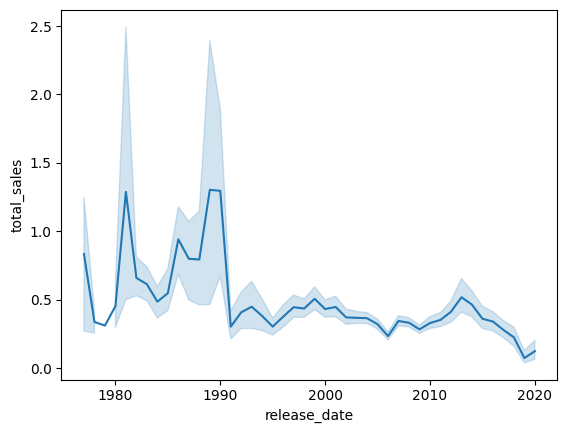

In [15]:
sns.lineplot(x='release_date',y='total_sales',data=df)

plt.show()

###Do any consoles seem to specialize in a particular genre?
####so i will make a scope to take consol and genre columns and add a counter

> Add blockquote



In [16]:
console_genre=df.groupby(['console','genre']).size().reset_index(name='count')
top_genre=console_genre.loc[console_genre.groupby('console')['count'].idxmax()]
top_genre

,console,genre,count
0,2600,Action,302
15,3DO,Misc,88
30,3DS,Misc,382
42,5200,Action,26
50,7800,Action,21
...,...,...,...
822,XOne,Action,309
843,XS,Action-Adventure,121
861,ZXS,Misc,13
871,iOS,Role-Playing,24


In [17]:
# To find the count of 'Action' games on the 'PS4', filter the DataFrame and use .shape[0] or .groupby()
filtered_df = df[(df['console'] == 'PS4') & (df['genre'] == 'Action')]

# Get the count
action_ps4_count = filtered_df.shape[0]
print(f"Number of Action games on PS4: {action_ps4_count}")

Number of Action games on PS4: 531


In [18]:
# Sort all consoles and genres by their game count in descending order
all_console_genres_sorted = console_genre.sort_values(by='count', ascending=False).reset_index(drop=True)
all_console_genres_sorted

,console,genre,count
0,PC,Adventure,1839
1,PC,Strategy,1629
2,PC,Misc,1375
3,PC,Role-Playing,1287
4,PC,Action,1279
...,...,...,...
881,XBL,Sandbox,1
882,XOne,Education,1
883,iOS,Music,1
884,3DS,MMO,1


In [24]:
# Group by genre and extract the console with the highest game count
top_console_per_genre = console_genre.loc[console_genre.groupby('genre')['count'].idxmax()]
top_console_per_genre_sorted = top_console_per_genre.sort_values(by='count', ascending=False).reset_index(drop=True)
top_console_per_genre_sorted.to_csv('top_console_per_genre_sorted.csv', index=False)
display(top_console_per_genre_sorted)

,console,genre,count
0,PC,Adventure,1839
1,PC,Strategy,1629
2,PC,Misc,1375
3,PC,Role-Playing,1287
4,PC,Action,1279
5,PC,Shooter,1192
6,PC,Simulation,988
7,PC,Puzzle,619
8,PC,Racing,582
9,PC,Sports,576


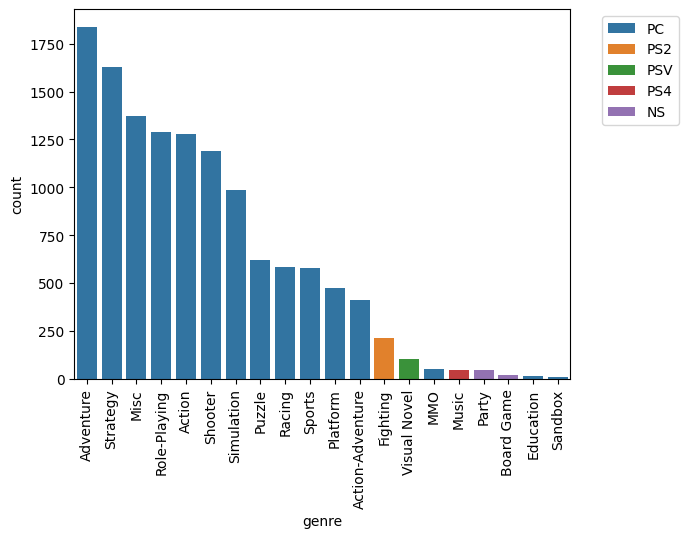

In [20]:
sns.barplot(x='genre', y='count', hue='console', data=top_console_per_genre_sorted)
plt.xticks(rotation=90)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

###What titles are popular in one region but flop in another?


In [21]:
titles_popular = df[['title', 'na_sales', 'jp_sales', 'pal_sales']].reset_index(drop=True)

titles_popular.head(20)

,title,na_sales,jp_sales,pal_sales
0,Grand Theft Auto V,6.37,0.99,9.85
1,Grand Theft Auto V,6.06,0.60,9.71
2,Grand Theft Auto: Vice City,8.41,0.47,5.49
3,Grand Theft Auto V,9.06,0.06,5.33
4,Call of Duty: Black Ops 3,6.18,0.41,6.05
5,Call of Duty: Modern Warfare 3,9.07,0.13,4.29
6,Call of Duty: Black Ops,9.76,0.11,3.73
7,Red Dead Redemption 2,5.26,0.21,6.21
8,Call of Duty: Black Ops II,8.27,0.07,4.32
9,Call of Duty: Black Ops II,4.99,0.65,5.88


In [25]:
# Group by title and sum the regional sales
regional_sales_by_title = df.groupby('title')[['na_sales', 'jp_sales', 'pal_sales', 'other_sales', 'total_sales']].sum()

# Sort by total_sales to show the most popular titles first
regional_sales_by_title = regional_sales_by_title.sort_values(by='total_sales', ascending=False).reset_index()
regional_sales_by_title.to_csv('regional_sales_by_title.csv', index=False)
# Show the top 10 titles
regional_sales_by_title.head(10)

,title,na_sales,jp_sales,pal_sales,other_sales,total_sales
0,Grand Theft Auto V,26.19,1.66,28.14,8.32,64.29
1,Call of Duty: Black Ops,17.65,0.59,9.45,3.31,30.99
2,Call of Duty: Modern Warfare 3,15.57,0.62,11.26,3.26,30.71
3,Call of Duty: Black Ops II,14.12,0.72,11.08,3.67,29.59
4,Call of Duty: Ghosts,15.06,0.49,9.60,3.65,28.80
5,Call of Duty: Black Ops 3,12.82,0.50,9.76,3.63,26.72
6,Call of Duty: Modern Warfare 2,13.54,0.46,8.08,2.95,25.02
7,Minecraft,9.07,2.50,9.48,2.96,24.01
8,Grand Theft Auto IV,11.60,0.58,7.64,2.72,22.53
9,Call of Duty: Advanced Warfare,10.66,0.35,7.99,2.81,21.78
